# PREDICCION DEL TRAFICO A 24 HS

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt 

## 1. Datos: tráfico horario por distrito (2023-2025)

In [3]:
# Creamos vista con la informacion de la intensidad por espira, dia, mes, año, hora 
spark.sql ("""
    CREATE OR REPLACE TEMP VIEW trafico_horario AS
    SELECT a.id_distrito,
           t.fecha_hora,
           t.anio, t.mes, t.hora, t.dia_semana,
           CAST(t.es_festivo AS INT) as es_festivo,
           AVG(a.intensidad) as trafico
    FROM gold.fact_trafico a
    JOIN gold.dim_tiempo t 
        ON a.id_tiempo = t.id_tiempo
    GROUP by a.id_distrito, t.fecha_hora, t.anio, t.mes, t.hora, t.dia_semana, t.es_festivo
    """)

spark.sql ("SELECT COUNT(*) AS filas FROM trafico_horario").show()
spark.sql("""
    SELECT CAST(fecha_hora AS STRING) AS fecha_hora, id_distrito, trafico
    FROM trafico_horario
    LIMIT 5
""").toPandas()

+------+
| filas|
+------+
|229635|
+------+



,fecha_hora,id_distrito,trafico
0,2024-01-01 18:00:00,11,350.183908
1,2024-01-28 09:00:00,6,382.442308
2,2024-01-25 07:00:00,13,223.906250
3,2024-01-31 09:00:00,7,1087.840909
4,2024-01-11 15:00:00,11,433.590909


In [4]:
# Para cada fila, necesitamos poner el trafico del dia anterior del mismo distrito
spark.sql("""
    CREATE OR REPLACE TEMP VIEW datos_modelo AS
    SELECT hoy.*,
           ayer.trafico AS trafico_ayer
    FROM trafico_horario hoy
    JOIN trafico_horario ayer
        ON  ayer.id_distrito = hoy.id_distrito
        AND ayer.fecha_hora  = hoy.fecha_hora - INTERVAL 24 HOURS
""")

spark.sql("SELECT COUNT(*) AS filas FROM datos_modelo").show()
spark.sql("""
    SELECT id_distrito, CAST(fecha_hora AS STRING) AS fecha_hora, hora, trafico, trafico_ayer
    FROM datos_modelo
    LIMIT 5
""").toPandas()

+------+
| filas|
+------+
|204052|
+------+



,id_distrito,fecha_hora,hora,trafico,trafico_ayer
0,13,2023-05-09 14:00:00,14,534.373134,642.223881
1,11,2025-08-21 14:00:00,14,426.170455,421.045455
2,10,2023-10-30 23:00:00,23,172.654867,179.324561
3,13,2023-09-12 00:00:00,0,131.876923,193.112903
4,2,2023-11-22 03:00:00,3,23.538462,31.333333


Algunas filas se perdieron por falta de mediciones. El dataset de tráfico tiene mas huevos relacionados con los datos de las horas del día anterior
25000 en total que representan un 11% 

In [5]:
# Calculamos umbral de error dia por dia. Nuestro modelo de prediccion deberia ser mejor que ese umbral

spark.sql("""
    SELECT ROUND(AVG(ABS(trafico - trafico_ayer)),2) AS mae_referencia
    FROM datos_modelo
    WHERE anio= 2025 and mes IN (6,7,8,9)
""").show()


+--------------+
|mae_referencia|
+--------------+
|         101.3|
+--------------+



La referencia se equivoca 101,3 veh/h. Nuestro modelo debería tener menos error

## 3. Modelo: Gradient Boosting (Spark MLlib)

In [6]:
from pyspark.ml.feature import VectorAssembler

datos = spark.table("datos_modelo")

# Separamos entrenamiento (2023-204) y test (2025 sólo de los meses con mediciones)
train_horario = datos.filter("anio <= 2024")
test_horario  = datos.filter("anio = 2025 AND mes in (6,7,8,9)")

# Juntamos las variables de entrada en una sola columna "features"
entradas = ["hora", "dia_semana", "mes", "es_festivo", "trafico_ayer"]
ensamblador = VectorAssembler(inputCols=entradas, outputCol="features")

train_horario = ensamblador.transform(train_horario)
test_horario  = ensamblador.transform(test_horario)

print("Entrenamiento:", train_horario.count(), "filas")
print("Test:", test_horario.count(), "filas")

/opt/conda/miniconda3/lib/python3.10/site-packages/scipy/__init__.py:155: UserWarning: A NumPy version >=1.18.5 and <1.26.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Entrenamiento: 155385 filas


Test: 47803 filas


In [7]:
from pyspark.ml.regression import GBTRegressor #modelo de Gradient Boosting de Spark
from pyspark.ml.evaluation import RegressionEvaluator

# Creamos y entrenamos el modelo
gbt = GBTRegressor (featuresCol ="features", labelCol="trafico", maxIter=50) # usa 50 árboles
modelo_gbt = gbt.fit (train_horario)

# Predecimos 2025
predicciones_2025 = modelo_gbt.transform (test_horario)

# Medimos el error
evaluador = RegressionEvaluator(labelCol="trafico", predictionCol="prediction", metricName="mae")
mae_gbt = evaluador.evaluate (predicciones_2025)
print("MAE Gradient Boosting:", round(mae_gbt, 2), "veh/h")

MAE Gradient Boosting: 108.54 veh/h


El modelo se equivoca más que la referencia (MAE de 108,54 frente a 101.3 veh/h).
Analizamos qué se puede mejorar del modelo.
Tambien es cierto que el tráfico del 2025 subió entre un 10-20% con respecto a años anteriores. El modelo de árboles no puede predecir valores más altos de los que vio al entrenar.

In [8]:
predicciones_2025.selectExpr(
    "ROUND(AVG(trafico), 1) AS real_medio",
    "ROUND(AVG(prediction), 1) AS predicho_medio").show()

+----------+--------------+
|real_medio|predicho_medio|
+----------+--------------+
|     539.9|         480.6|
+----------+--------------+



Se comprueba que el modelo predice 480 veh/h cuando la realidad fue 540 aprox. Aprendió el nivel de tráfico de 2023-2024 y no puede predecir correctamente mayor tráfico.

Vamos a agregar el distrito y tambien vamos a cambiar que la prediccion sea la variacion respecto al dia de ayer.

### Modelo ajustado

In [9]:
spark.sql("""
    CREATE OR REPLACE TEMP VIEW datos_modelo_v2 AS
    SELECT *,
           trafico - trafico_ayer AS diferencia
    FROM datos_modelo
""")

spark.sql("SELECT COUNT(*) AS filas FROM datos_modelo_v2").show()
spark.sql("""SELECT id_distrito, CAST(fecha_hora AS STRING), hora, ROUND(trafico,1) AS trafico, ROUND(trafico_ayer,1) AS trafico_ayer, ROUND(diferencia,1) AS diferencia FROM datos_modelo_v2 LIMIT 5""").toPandas()


+------+
| filas|
+------+
|204052|
+------+



,id_distrito,fecha_hora,hora,trafico,trafico_ayer,diferencia
0,13,2023-05-09 14:00:00,14,534.4,642.2,-107.9
1,11,2025-08-21 14:00:00,14,426.2,421.0,5.1
2,10,2023-10-30 23:00:00,23,172.7,179.3,-6.7
3,13,2023-09-12 00:00:00,0,131.9,193.1,-61.2
4,2,2023-11-22 03:00:00,3,23.5,31.3,-7.8


Con este ejemplo se puede ver claramente como la diferencia entre uno dia y otro puede ser amplia (-107). Por eso en vez de predecir el trafico directamente, el modelo va a predecir esta diferencia: cuánto cambia el tráfico respecto a ayer. Luego sumaremos esta diferencia al trafico de ayer para obtener la prediccion final

In [10]:
# Separamos test y train con este nuevo df
from pyspark.ml.feature import VectorAssembler

datos_v2 = spark.table("datos_modelo_v2")

# Separamos entrenamiento (2023-2024) y test (2025 sólo de los meses con mediciones)
train_horario_v2 = datos_v2.filter("anio <= 2024")
test_horario_v2  = datos_v2.filter("anio = 2025 AND mes in (6,7,8,9)")

# Juntamos las variables de entrada en una sola columna "features". Agregamos distrito. Eliminamos trafico_ayer para que no lo tome en cuenta generando confusiones
entradas_v2 = ["id_distrito", "hora", "dia_semana", "mes", "es_festivo"]
ensamblador_v2 = VectorAssembler(inputCols=entradas_v2, outputCol="features")

train_horario_v2 = ensamblador_v2.transform(train_horario_v2)
test_horario_v2  = ensamblador_v2.transform(test_horario_v2)

print("Entrenamiento:", train_horario_v2.count(), "filas")
print("Test:", test_horario_v2.count(), "filas")

Entrenamiento: 155385 filas


Test: 47803 filas


In [11]:
from pyspark.ml.regression import GBTRegressor #modelo de Gradient Boosting de Spark
from pyspark.ml.evaluation import RegressionEvaluator

# Creamos y entrenamos el modelo v2
gbt_v2 = GBTRegressor (featuresCol ="features", labelCol="diferencia", maxIter=50) # usa 50 árboles
modelo_gbt_v2 = gbt_v2.fit (train_horario_v2)

# Predecimos 2025
predicciones_2025_v2 = (modelo_gbt_v2.transform (test_horario_v2)
                       .selectExpr("*", "trafico_ayer + prediction AS prediccion_final"))

# Medimos el error
evaluador_v2 = RegressionEvaluator(labelCol="trafico", predictionCol="prediccion_final", metricName="mae")
mae_gbt_v2 = evaluador_v2.evaluate (predicciones_2025_v2)
print("MAE Gradient Boosting v2:", round(mae_gbt_v2, 2), "veh/h")

MAE Gradient Boosting v2: 78.45 veh/h


Este modelo ya sí tiene menor error que la referencia. Se equivoca unos 23 veh/h menos que la referencia (la diferencia predicha es muy cercana a la real). 

In [12]:
predicciones_2025_v2.selectExpr(
    "ROUND(AVG(trafico_ayer), 1) AS media_ayer",
    "ROUND(AVG(diferencia), 1) AS media_diferencia_real",
    "ROUND(AVG(prediction), 1) AS media_diferencia_predicha"
).toPandas()

,media_ayer,media_diferencia_real,media_diferencia_predicha
0,544.6,-4.7,-3.9


In [13]:
# Que variables usa el modelo?
for nombre, importancia in zip(entradas_v2, modelo_gbt_v2.featureImportances):
    print(nombre, ":", round(importancia * 100, 1), "%")

id_distrito : 8.3 %
hora : 44.1 %
dia_semana : 34.7 %
mes : 9.1 %
es_festivo : 3.9 %


La variable más importante es la hora (44%), seguida por el día de la semana (34.7 %), el mes (9 %)y el distrito (8 %). El modelo usa los mismos patrones que encontramos en el análisis temporal: el ciclo diario y el efecto fin de semana. Los festivos pesan poco (3.9 %) porque son pocos días al año.

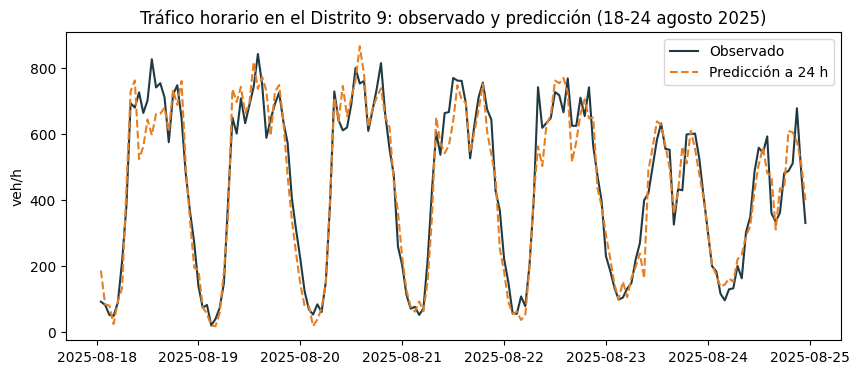

In [14]:
# Al intentar graficar nos dio error de compatibilidad entre la version de Spark del cluster y la de pandas.
# En este caso el error es con las fechas. Lo arregalmos
import io
import pandas as pd
import matplotlib.pyplot as plt
from google.cloud import storage

filas = (predicciones_2025_v2
         .filter("id_distrito = 9 AND fecha_hora >= '2025-08-18' AND fecha_hora < '2025-08-25'")
         .select("fecha_hora", "trafico", "prediccion_final")
         .orderBy("fecha_hora")
         .collect())

semana = pd.DataFrame(filas, columns=["fecha_hora", "trafico", "prediccion_final"])

plt.figure(figsize=(10, 4))
plt.plot(semana["fecha_hora"], semana["trafico"], color="#203A43", label="Observado")
plt.plot(semana["fecha_hora"], semana["prediccion_final"], color="#E67E22", linestyle="--", label="Predicción a 24 h")
plt.title("Tráfico horario en el Distrito 9: observado y predicción (18-24 agosto 2025)")
plt.ylabel("veh/h")
plt.legend()

# Guardar en el bucket
buffer = io.BytesIO()
plt.savefig(buffer, format="png", dpi=300, bbox_inches="tight")
bucket = storage.Client().bucket("tfm_unir1")
bucket.blob("processed/figuras/trafico_prediccion_24h_distrito9.png").upload_from_string(
    buffer.getvalue(), content_type="image/png")

plt.show()

El modelo acierta el ciclo diario: casi nada de madrugada y entre 600 y 800 veh/h durante el día. Capta el fin de semana. Donde más se equivoca es en picos sueltos de algunas horas.

**Conclusión:** El modelo Gradient Boosting predice el tráfico de cada distrito con 24 horas de anticipación. Se entrenó con 2023-2024 (155.385 horas) y se evaluó con junio a septiembre de 2025 (47.803 horas).

El primer intento, que predecía directamente el tráfico, tenía errores mayores que la referencia porque en 2025 el tráfico es más alto que en los años de entrenamiento (MAE de 108,54 frente a 101,3 veh/h de la referencia). Por eso el modelo final predice el cambio respecto al día anterior, usando solo el calendario, y le suma el tráfico de ayer.

Se equivoca un 23 % menos que la referencia (MAE de 78,45 frente a 101,3 veh/h). Acierta el ciclo diario y la bajada del fin de semana, pero no los picos puntuales.

Para mejorarlo harían falta datos de tráfico más completos, sin huecos ni periodos con valores repetidos.

## 4. Guardar las predicciones en fact_prediccion

In [ ]:
# Guardamos en la GOLD
predicciones_2025_v2.createOrReplaceTempView ("prediccion_trafico_24h")

spark.sql("""
    INSERT INTO gold.fact_prediccion
    SELECT 'gradient_boosting'                                AS modelo,
           'trafico'                                              AS indicador,
           '24h'                                              AS horizonte,
           'horaria'                                          AS granularidad,
           CURRENT_DATE()                                     AS fecha_ejecucion,
           TO_DATE(fecha_hora)                                AS fecha_prevista,
           CAST(DATE_FORMAT(fecha_hora, 'yyyyMMddHH') AS INT) AS id_tiempo,
           CAST (NULL AS STRING),
           ROUND(prediccion_final, 1)                               AS valor_previsto,
           CAST(NULL AS DOUBLE)                               AS valor_bajo,
           CAST(NULL AS DOUBLE)                               AS valor_alto,
           id_distrito                                        AS id_distrito
    FROM prediccion_trafico_24h
""")

In [15]:
spark.sql("SELECT modelo, COUNT(*) AS filas FROM gold.fact_prediccion GROUP BY modelo").show()

+-----------------+------+
|           modelo| filas|
+-----------------+------+
|gradient_boosting|100677|
|         sarima_b|    60|
| regresion_lineal|    10|
|         sarima_a|    60|
+-----------------+------+

